In [1]:
# Practia 11. Realizada por Angel Antolin
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics.pairwise import euclidean_distances

from tqdm.notebook import tqdm

# CLASE Kmedias_moda

In [2]:
#Obtenet datos del dataset
dry_bean = fetch_ucirepo(id=602) 
   
X = dry_bean.data.features 
y = dry_bean.data.targets 

#Escalar datos de [0, 1]
X_escalada = MinMaxScaler().fit_transform(X)


#Creación de la clase kmedias_moda
class kmedias_moda:

    #Metodo init, inicializa el KMeans con los clusters
    def __init__(self, k):
        
        self.k = k
        
        self.kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        
        self.modas = {}

    #Metodo fit calcular clusters y baricentros siguiendo el criterio de la moda
    def fit(self, X_train, y_train):
        
        self.kmeans.fit(X_train)
        
        # Asigna etiquetas a cada cluster según la moda
        for i in range(self.k):
            
            # Extraemos las etiquetas reales de las muestras que cayeron en este cluster
            etiquetas_cluster = y_train[self.kmeans.labels_ == i]
            
            if len(etiquetas_cluster) > 0:
                
                # Calculamos la moda: el valor que más se repite
                valores, conteos = np.unique(etiquetas_cluster, return_counts=True)
                etiqueta_mas_frecuente = valores[np.argmax(conteos)]
                self.modas[i] = etiqueta_mas_frecuente
            
            else:
                
                # Por si un cluster se queda vacío 
                self.modas[i] = y_train[0]
        
    #Metodo predict devuelve la etiqueta correspondiente al cluster
    def predict(self, X_test):

    
        clusters_asignados = self.kmeans.predict(X_test)
        
        # Devolvemos la etiqueta (moda) que le corresponde a cada cluster
        etiquetas_finales = []
        for c in clusters_asignados:
            
            etiqueta_traducida = self.modas[c]
            etiquetas_finales.append(etiqueta_traducida)
            
        return np.array(etiquetas_finales)

    #Metodo score obtiene tasa de acierto
    def score(self, X_test, y_test):
        
        # Obtenemos las predicciones
        predicciones = self.predict(X_test)
        
        # Calculamos la tasa de aciertos (accuracy)
        return accuracy_score(y_test, predicciones)

# VALIDACION CRUZADA DE KMEANS

Nº Clusters:   0%|          | 0/29 [00:00<?, ?it/s]

,Entrena,Verifica
n_clusters,,
2,0.399383,0.399383
3,0.440534,0.440894
4,0.549237,0.549409
5,0.659744,0.659614
6,0.800798,0.800897
7,0.798537,0.798693
8,0.857558,0.857763
9,0.842366,0.841673
10,0.827068,0.824628



El número óptimo de clusters para la capa oculta es: 30 con un 0.8778 de acierto.


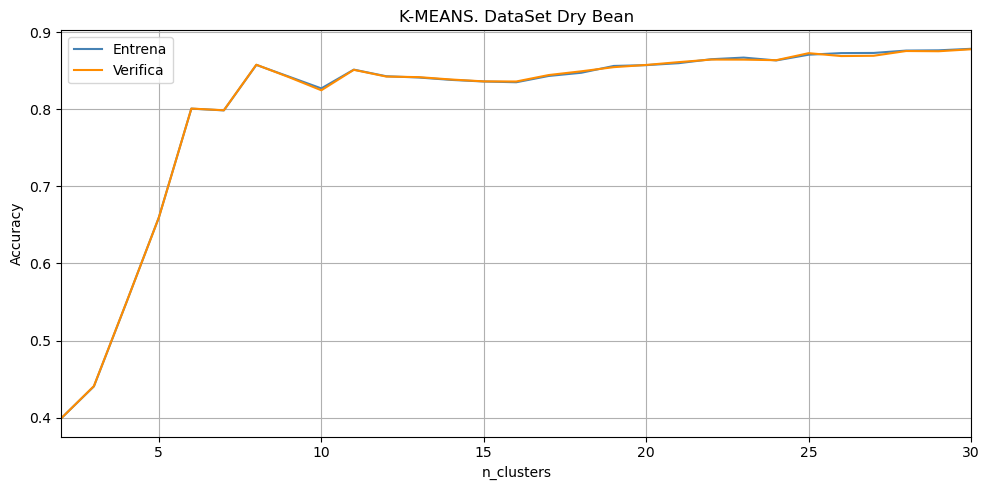

In [3]:
#Validacion Cruzada y rango de clusters
y = np.array(y)

kf = StratifiedKFold(n_splits = 10, shuffle = True, random_state=42)

rango_clusters = range(2, 31)

resultados = [] 

#Bucle principal, entrena los clusters
for k in tqdm(rango_clusters, desc= "Nº Clusters"):

    aciertos_train = []
    aciertos_test = []

    #Bucle interno para las 10 carpetas
    for train_indice, test_indice in kf.split(X_escalada, y):

        #Separar entrenamiento de test
        X_train, X_test = X_escalada[train_indice], X_escalada[test_indice]
        y_train, y_test = y[train_indice], y[test_indice]

        #Usar modelo
        modelo = kmedias_moda(k)
        modelo.fit(X_train, y_train)

        #Añadir tasa de aciertos
        aciertos_train.append(modelo.score(X_train, y_train))
        aciertos_test.append(modelo.score(X_test, y_test))

    #Tabla resumen
    resultados.append({

        'n_clusters': k,
        'Entrena': np.mean(aciertos_train),
        'Verifica': np.mean(aciertos_test)
    })

# Creación del DataFrame de resultados
df_kmeans = pd.DataFrame(resultados).set_index('n_clusters')

display(df_kmeans)

# Extraemos el número óptimo de clusters 
k_optimo = df_kmeans['Verifica'].idxmax()
print(f"\nEl número óptimo de clusters para la capa oculta es: {k_optimo} con un {df_kmeans['Verifica'].max():.4f} de acierto.")

# Grafica
plt.figure(figsize=(10, 5))
plt.plot(df_kmeans.index, df_kmeans['Entrena'], color='steelblue', label='Entrena')
plt.plot(df_kmeans.index, df_kmeans['Verifica'], color='darkorange', label='Verifica')
plt.title('K-MEANS. DataSet Dry Bean')
plt.xlabel('n_clusters')
plt.ylabel('Accuracy')
plt.xlim(2, 30)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
    

# CLASE RBF

In [4]:
# Creación del objeto de la capa oculta RBF
class oculta_rbf:
    
    def __init__(self, k):
        
        self.k = k
        self.kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        self.centros = None
        self.sigmas = None

    #Metodo fit ajusta clusters, baricentros y sigma
    def fit(self, X_train):
        
        # Encontramos los clusters y baricentros
        self.kmeans.fit(X_train)
        self.centros = self.kmeans.cluster_centers_
        
        # Calcular los sigmas aplicando distancia al resto de centros 
        self.sigmas = np.zeros(self.k)
        distancias_centros = euclidean_distances(self.centros, self.centros)
        
        for i in range(self.k):
            
            # Sumamos las distancias y dividimos por (k - 1) para sacar la media, 
            # descartando la distancia de 0 consigo mismo
            self.sigmas[i] = np.sum(distancias_centros[i]) / (self.k - 1)
            
            # Control de seguridad por si algún sigma da 0
            if self.sigmas[i] == 0:
                self.sigmas[i] = 1e-9

    #Aplica funcion de base radial
    def output(self, X):
        
        # Calculamos la distancia de cada muestra a cada uno de los baricentros
        distancias = euclidean_distances(X, self.centros)
        
        # Aplicamos la función Gaussiana RBF a la matriz de distancias
        # Fórmula: exp( -distancia^2 / (2 * sigma^2) )
        salida_rbf = np.exp(- (distancias**2) / (2 * (self.sigmas**2)))
        
        return salida_rbf

# EXPERIMENTO CON SVM

In [6]:
y = np.array(y).ravel()
#Grados y tabla de resultados
grados_polinomio = range(2, 6)

resultados_svm = []


for grado in tqdm(grados_polinomio, desc = "Grado Polinomio"):

    aciertos_test = []

    for train_indice, test_indice in kf.split(X_escalada, y):

        #Separar entrenamiento de test
        X_train, X_test = X_escalada[train_indice], X_escalada[test_indice]
        y_train, y_test = y[train_indice], y[test_indice]

        #Capa coulta con rbf
        capa_oculta = oculta_rbf(k_optimo)
        capa_oculta.fit(X_train)

        #Obtener los grados de pertenencia
        X_train_transformado = capa_oculta.output(X_train)
        X_test_transformado = capa_oculta.output(X_test)

        #Instanciar la SVM con el grado y el polinomio
        svm = SVC(kernel= 'poly', degree = grado, random_state = 42)

        svm.fit(X_train_transformado, y_train)

        #Sacar tasa de aciertos
        predicciones = svm.predict(X_test_transformado)
        aciertos_test.append(accuracy_score(y_test, predicciones))

    resultados_svm.append({
        'Grado_Polinomio': grado,
        'Aciertos_Verifica': np.mean(aciertos_test)
    })

# Construcción de la tabla y extracción del resultado óptimo
df_svm = pd.DataFrame(resultados_svm).set_index('Grado_Polinomio')

print("\n--- Resultados SVM con Kernel Polinomial ---")
display(df_svm)

mejor_grado = df_svm['Aciertos_Verifica'].idxmax()
mejor_acierto = df_svm['Aciertos_Verifica'].max()

print(f"\nEl grado óptimo para el kernel polinómico de la SVM es: {mejor_grado} (Tasa de acierto: {mejor_acierto:.4f})")

        

Grado Polinomio:   0%|          | 0/4 [00:00<?, ?it/s]


--- Resultados SVM con Kernel Polinomial ---


,Aciertos_Verifica
Grado_Polinomio,
2,0.922490
3,0.925797
4,0.928588
5,0.929250



El grado óptimo para el kernel polinómico de la SVM es: 5 (Tasa de acierto: 0.9292)
